In [3]:
# Import Libs
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import xesmf as xe

In [4]:
# Isolate the northern boundary, plot against the mask
tidal_data = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/forcing/tu_segment_002.nc")
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc")
bathy = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/bathymetry.nc")


In [34]:
tidal_data

<xarray.Dataset>
Dimensions:             (time: 1, constituent: 10, ny_segment_002: 1, nx_segment_002: 1481)
Coordinates:
    lon_segment_002     (nx_segment_002) float64 -98.75 -98.71 ... -37.49 -37.45
    lat_segment_002     (nx_segment_002) float64 52.78 52.78 ... 58.37 58.38
  * time                (time) datetime64[ns] 2000-01-01
Dimensions without coordinates: constituent, ny_segment_002, nx_segment_002
Data variables:
    uamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    vamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    uphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 ...
    vphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 ...

In [6]:
mask = bathy.depth[-1,] ==0

In [12]:
bathy.lath


<xarray.DataArray 'lath' (lath: 780)>
array([ 5.242669,  5.325648,  5.408616, ..., 58.437085, 58.488903, 58.540689])
Coordinates:
  * lath     (lath) float64 5.243 5.326 5.409 5.492 ... 58.39 58.44 58.49 58.54
Attributes:
    longname:  Nominal latitude of cell center points
    units:     degrees_east

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

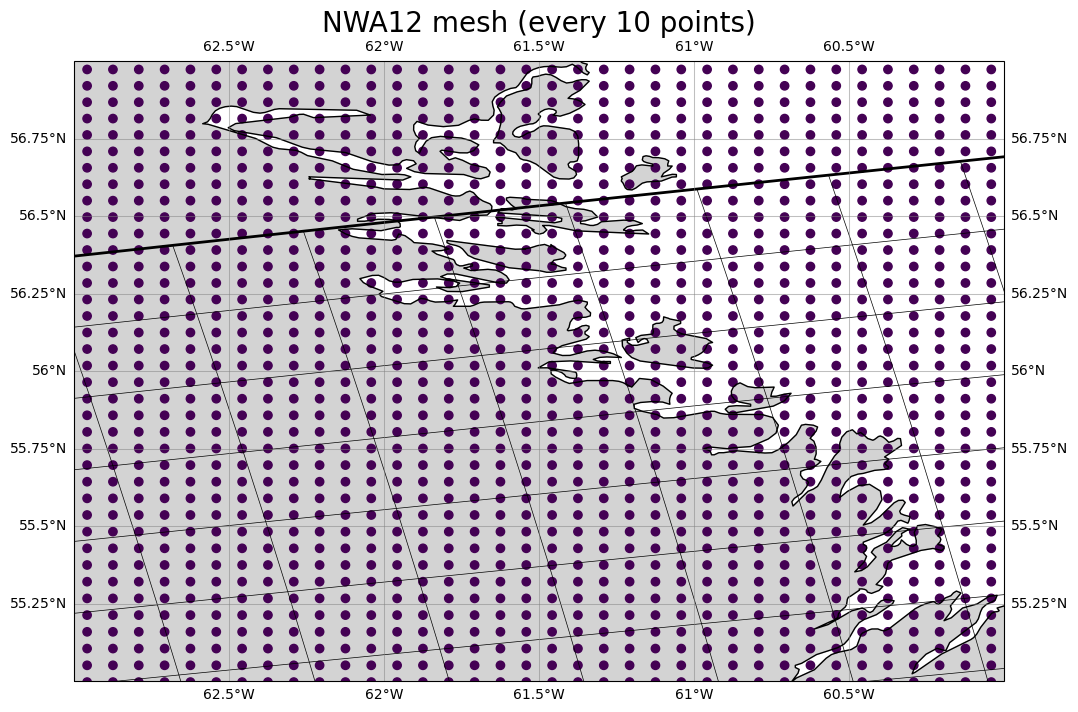

In [17]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-63, -60, 55, 57], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

#ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
#ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
#ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
#scatter = ax.scatter(tidal_data.lon_segment_002.values, tidal_data.lat_segment_002.values, c= tidal_data.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

#plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

# Scatter plot for bathymetry data
bathy_lon, bathy_lat = np.meshgrid(bathy.lonh.values, bathy.lath.values)
scatter_bathy = ax.scatter(bathy_lon, bathy_lat, c=bathy.depth, transform=ccrs.PlateCarree())
plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



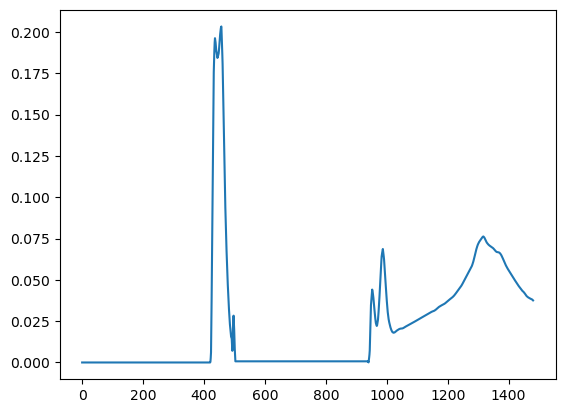

In [ ]:
plt.plot(tidal_data.uamp_segment_002[0][0][-1])
plt.plot(mask[-1])

In [1]:
num = "002"

tidal_data = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/tu_segment_{}.nc".format(num))
tidal_data_before = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/crr/tides_dev/outputs/forcing/tu_segment_{}.nc".format(num))

tidal_data_elv = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/tides-three-boundary-err/tz_segment_{}.nc".format(num))
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc")
hgrid

tpx = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/inputs_rm6/tidal_data/h_tpxo9.v1.nc")
bathy = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/tides-three-boundary-err/bathymetry.nc")    

NameError: name 'xr' is not defined

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

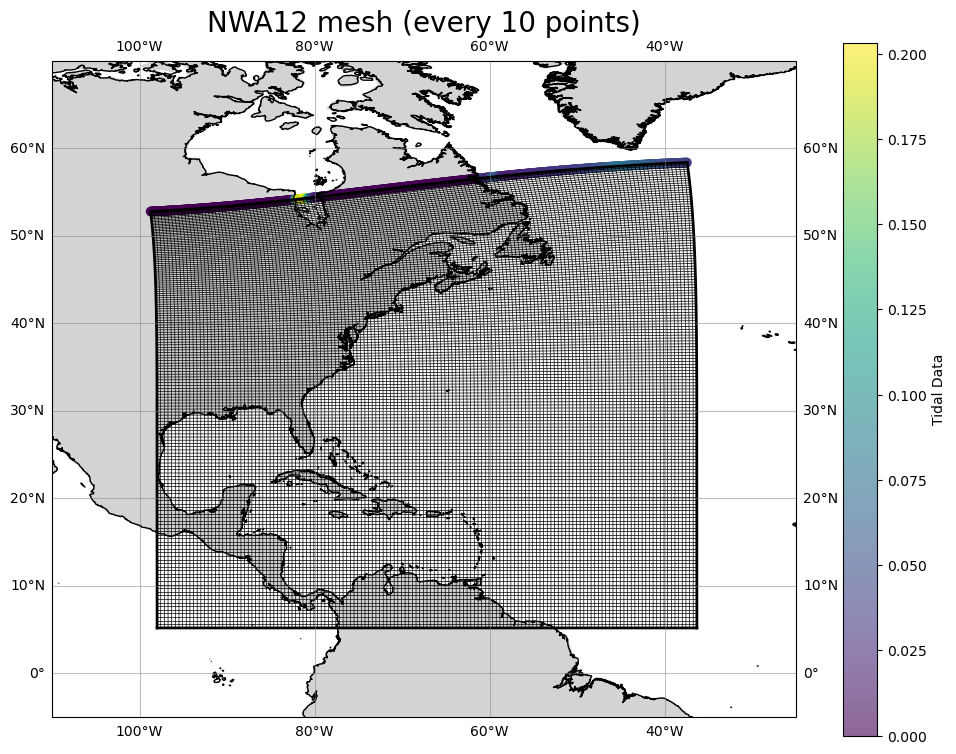

In [10]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data.lon_segment_002.values, tidal_data.lat_segment_002.values, c= tidal_data.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

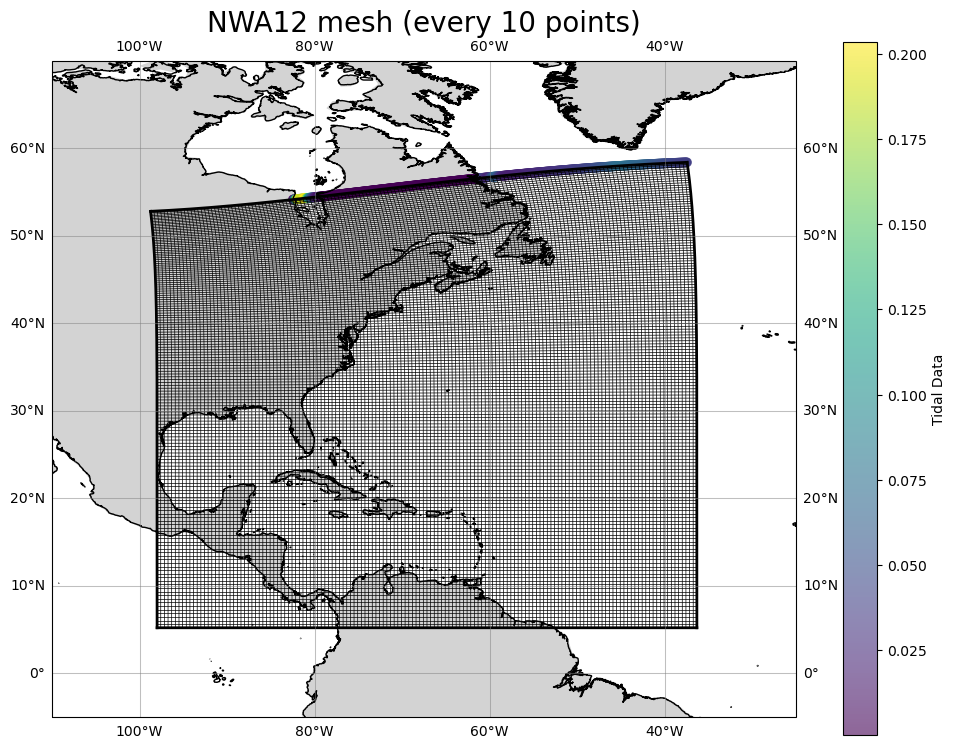

In [11]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_before.lon_segment_002.values, tidal_data_before.lat_segment_002.values, c= tidal_data_before.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



In [117]:
tidal_data.uamp_segment_001[0][0]

<xarray.DataArray 'uamp_segment_001' (ny_segment_001: 1, nx_segment_001: 1529)>
array([[     nan,      nan,      nan, ..., 0.0411  , 0.040581, 0.040064]],
      dtype=float32)
Coordinates:
    lon_segment_001  (nx_segment_001) float64 -99.02 -98.98 ... -35.51 -35.46
    lat_segment_001  (nx_segment_001) float64 50.02 50.02 50.03 ... 54.29 54.3
    time             datetime64[ns] 2000-01-01
Dimensions without coordinates: ny_segment_001, nx_segment_001

In [112]:
tidal_data_elv

<xarray.Dataset>
Dimensions:             (time: 1, constituent: 1, ny_segment_001: 1, nx_segment_001: 1529)
Coordinates:
    lon_segment_001     (nx_segment_001) float64 ...
    lat_segment_001     (nx_segment_001) float64 ...
  * time                (time) datetime64[ns] 2000-01-01
Dimensions without coordinates: constituent, ny_segment_001, nx_segment_001
Data variables:
    zamp_segment_001    (time, constituent, ny_segment_001, nx_segment_001) float64 ...
    zphase_segment_001  (time, constituent, ny_segment_001, nx_segment_001) float64 ...

In [27]:
tidal_data.uphase_segment_002[0][0].values

array([[       nan,        nan,        nan, ..., 0.7905394 , 0.7859369 ,
        0.78134406]], dtype=float32)

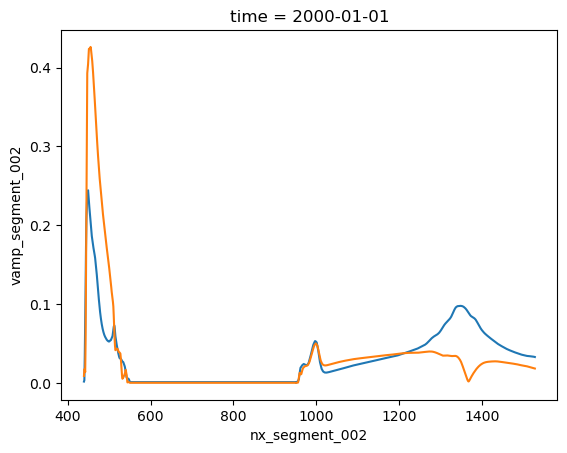

In [6]:
tidal_data["uamp_segment_{}".format(num)].plot()
tidal_data["vamp_segment_{}".format(num)].plot()

In [7]:
tidal_data["lat_segment_{}".format(num)].values

array([53.10461119, 53.10637868, 53.10815442, ..., 58.9885574 ,
       58.99025038, 58.9919359 ])

In [8]:
tidal_data["lon_segment_{}".format(num)].values

array([-99.32939001, -99.29136467, -99.25333852, ..., -36.04152656,
       -35.99485006, -35.94816842])

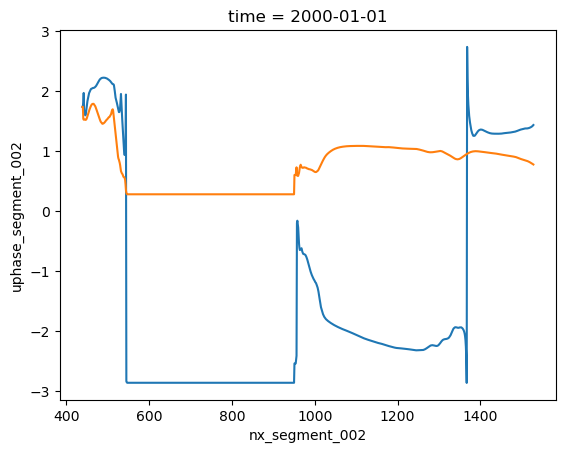

In [9]:
tidal_data["vphase_segment_{}".format(num)].plot()
tidal_data["uphase_segment_{}".format(num)].plot()


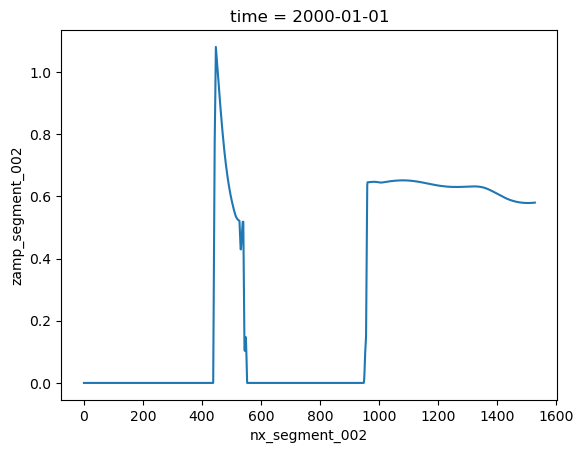

In [10]:
tidal_data_elv["zamp_segment_{}".format(num)].plot()


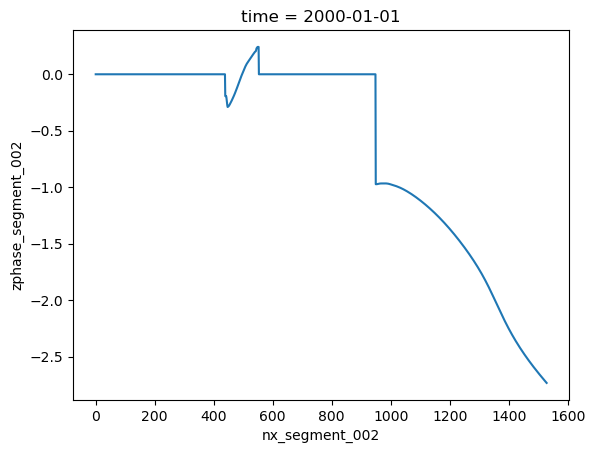

In [11]:
tidal_data_elv["zphase_segment_{}".format(num)].plot()